<a href="https://colab.research.google.com/github/ujwalreddy18/Twitter-spam-detection/blob/main/spam_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spam Message Detection with NLP

Classifies short text messages as **spam** or **ham** (legitimate) using the
[UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (`spam.csv`).

**Pipeline:** cleaning & de-duplication → text normalisation → TF-IDF (word + character n-grams) →
Naive Bayes / Logistic Regression / Linear SVM → stratified cross-validation → held-out test evaluation → error analysis.

Because only ~13% of messages are spam, accuracy alone is misleading. Models are compared on
**spam F1, precision and recall**, plus ROC-AUC and PR-AUC.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, make_scorer, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

## 1. Load and clean the data

In [2]:
# The file is Latin-1 encoded and has three empty trailing columns
df = pd.read_csv("spam.csv", encoding="latin-1")
df = df[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"})
df["text"] = df["text"].str.replace("å£", "£", regex=False)   # fix mis-encoded pound sign
print("Raw rows:", len(df))

dupes = df.duplicated(subset="text").sum()
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print(f"Removed {dupes} duplicate messages -> {len(df)} rows")

df["y"] = (df["label"] == "spam").astype(int)
df.head()

Raw rows: 5572
Removed 403 duplicate messages -> 5169 rows


,label,text,y
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",0


Duplicates are removed **before** splitting; otherwise identical messages land in both train and test and inflate the scores.

## 2. Exploratory analysis

label
ham     4516
spam     653
Name: count, dtype: int64 

Spam share: 12.6%
       n_chars  n_digits  has_url
label                            
ham      70.46      0.29     0.00
spam    137.48     15.45     0.16


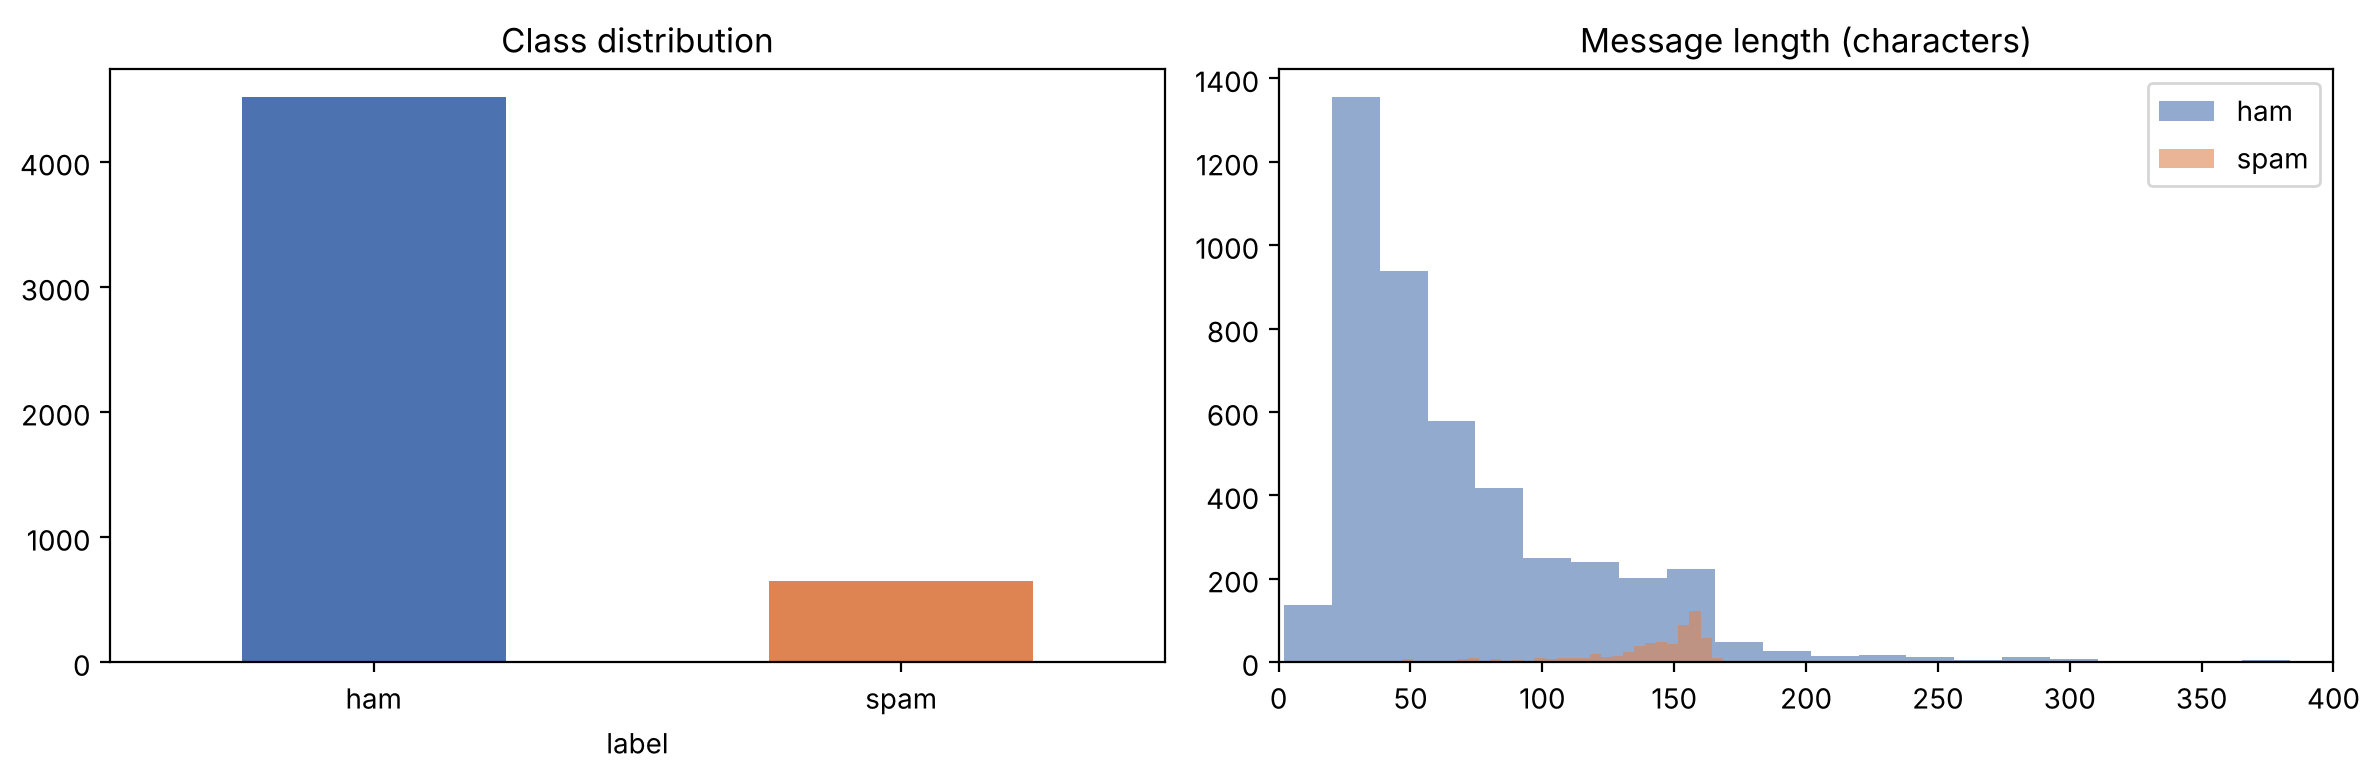

In [3]:
counts = df["label"].value_counts()
print(counts, "\n")
print(f"Spam share: {df['y'].mean():.1%}")

df["n_chars"] = df["text"].str.len()
df["n_digits"] = df["text"].str.count(r"\d")
df["has_url"] = df["text"].str.contains(r"http|www\.|\.com", case=False)
print(df.groupby("label")[["n_chars", "n_digits", "has_url"]].mean().round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452"], rot=0, title="Class distribution")
for lab, col in [("ham", "#4C72B0"), ("spam", "#DD8452")]:
    ax[1].hist(df.loc[df.label == lab, "n_chars"], bins=50, alpha=0.6, label=lab, color=col)
ax[1].set(title="Message length (characters)", xlim=(0, 400)); ax[1].legend()
plt.tight_layout(); plt.show()

Spam messages are longer and contain far more digits (phone numbers, short codes, prices). That's why the
normalisation step keeps these signals as tokens instead of deleting them.

## 3. Text normalisation

In [4]:
def normalise(text: str) -> str:
    t = text.lower()
    t = re.sub(r"(https?://\S+|www\.\S+|\S+\.(com|net|org|co\.uk)\S*)", " urltoken ", t)
    t = re.sub(r"\S+@\S+", " emailtoken ", t)
    t = re.sub(r"[£$€]\s?\d+(\.\d+)?|\d+(\.\d+)?\s?(p|pence|pounds?)\b", " moneytoken ", t)
    t = re.sub(r"\b\d{5,}\b", " phonetoken ", t)      # phone numbers / short codes
    t = re.sub(r"\d+", " numtoken ", t)
    t = re.sub(r"[^a-z!? ]", " ", t)                    # keep ! and ? (common in spam)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["text"].apply(normalise)
df[["text", "clean"]].sample(5, random_state=1)

,text,clean
2971,I've been barred from all B and Q stores for life!?This twat in orange dungerees came up to me and asked if I wanted...,i ve been barred from all b and q stores for life!?this twat in orange dungerees came up to me and asked if i wanted...
3830,Gam gone after outstanding innings.,gam gone after outstanding innings
3066,Am okay. Will soon be over. All the best,am okay will soon be over all the best
3231,Welcome! Please reply with your AGE and GENDER to begin. e.g 24M,welcome! please reply with your age and gender to begin e g numtoken m
2139,Alrite jod hows the revision goin? Keris bin doin a smidgin. N e way u wanna cum over after college?xx,alrite jod hows the revision goin? keris bin doin a smidgin n e way u wanna cum over after college?xx


Unlike the usual "strip everything but letters" approach, URLs, money amounts and phone numbers are replaced with
placeholder tokens, so the model learns *"this message contains a phone number"* without memorising specific numbers.

## 4. Train / test split (stratified)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["y"], test_size=0.2, stratify=df["y"], random_state=RANDOM_STATE)
print(f"Train: {len(X_train)}  ({y_train.mean():.1%} spam)")
print(f"Test : {len(X_test)}  ({y_test.mean():.1%} spam)")

Train: 4135  (12.6% spam)
Test : 1034  (12.7% spam)


## 5. Models and cross-validation

In [6]:
def features():
    # Word unigrams+bigrams capture phrases ("call now", "free entry");
    # character n-grams catch obfuscations and misspellings ("fr33", "txt").
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)),
    ])

models = {
    "Baseline (always ham)": Pipeline([("tfidf", features()), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Multinomial NB":        Pipeline([("tfidf", features()), ("clf", MultinomialNB(alpha=0.1))]),
    "Complement NB":         Pipeline([("tfidf", features()), ("clf", ComplementNB(alpha=0.3))]),
    "Logistic Regression":   Pipeline([("tfidf", features()), ("clf", LogisticRegression(C=10, class_weight="balanced", max_iter=2000))]),
    "Linear SVM":            Pipeline([("tfidf", features()), ("clf", LinearSVC(C=1, class_weight="balanced"))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy",
           "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1"}

rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{k: s[f"test_{k}"].mean() for k in scoring},
                 "f1_std": s["test_f1"].std()})
cv_results = pd.DataFrame(rows).set_index("model").round(4)
cv_results.sort_values("f1", ascending=False)

,accuracy,precision,recall,f1,f1_std
model,,,,,
Linear SVM,0.9908,0.9822,0.9444,0.9629,0.0050
Logistic Regression,0.9894,0.9651,0.9501,0.9575,0.0094
Multinomial NB,0.9855,0.9359,0.9502,0.9430,0.0116
Complement NB,0.9770,0.8743,0.9559,0.9131,0.0120
Baseline (always ham),0.8738,0.0000,0.0000,0.0000,0.0000


The baseline makes the point: it scores ~87% **accuracy** while catching **zero** spam.
Spam F1 is the main metric used to pick a model. Class weighting (`class_weight="balanced"`) makes the
linear models pay more attention to the minority spam class.

## 6. Evaluate on the held-out test set

In [7]:
results, fitted = [], {}
for name, model in models.items():
    if name.startswith("Baseline"):
        continue
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    score = (model.decision_function(X_test) if hasattr(model, "decision_function")
             else model.predict_proba(X_test)[:, 1])
    fitted[name] = model
    results.append({"model": name,
                    "accuracy": accuracy_score(y_test, pred),
                    "precision": precision_score(y_test, pred),
                    "recall": recall_score(y_test, pred),
                    "f1": f1_score(y_test, pred),
                    "roc_auc": roc_auc_score(y_test, score),
                    "pr_auc": average_precision_score(y_test, score)})
test_results = pd.DataFrame(results).set_index("model").sort_values("f1", ascending=False).round(4)
test_results

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Linear SVM,0.9894,0.9615,0.9542,0.9579,0.9962,0.9871
Logistic Regression,0.9884,0.9612,0.9466,0.9538,0.9951,0.9843
Multinomial NB,0.9845,0.9323,0.9466,0.9394,0.9958,0.9847
Complement NB,0.9797,0.8873,0.9618,0.9231,0.9941,0.9813


Best model: Linear SVM 

              precision    recall  f1-score   support

         ham     0.9934    0.9945    0.9939       903
        spam     0.9615    0.9542    0.9579       131

    accuracy                         0.9894      1034
   macro avg     0.9775    0.9743    0.9759      1034
weighted avg     0.9893    0.9894    0.9893      1034



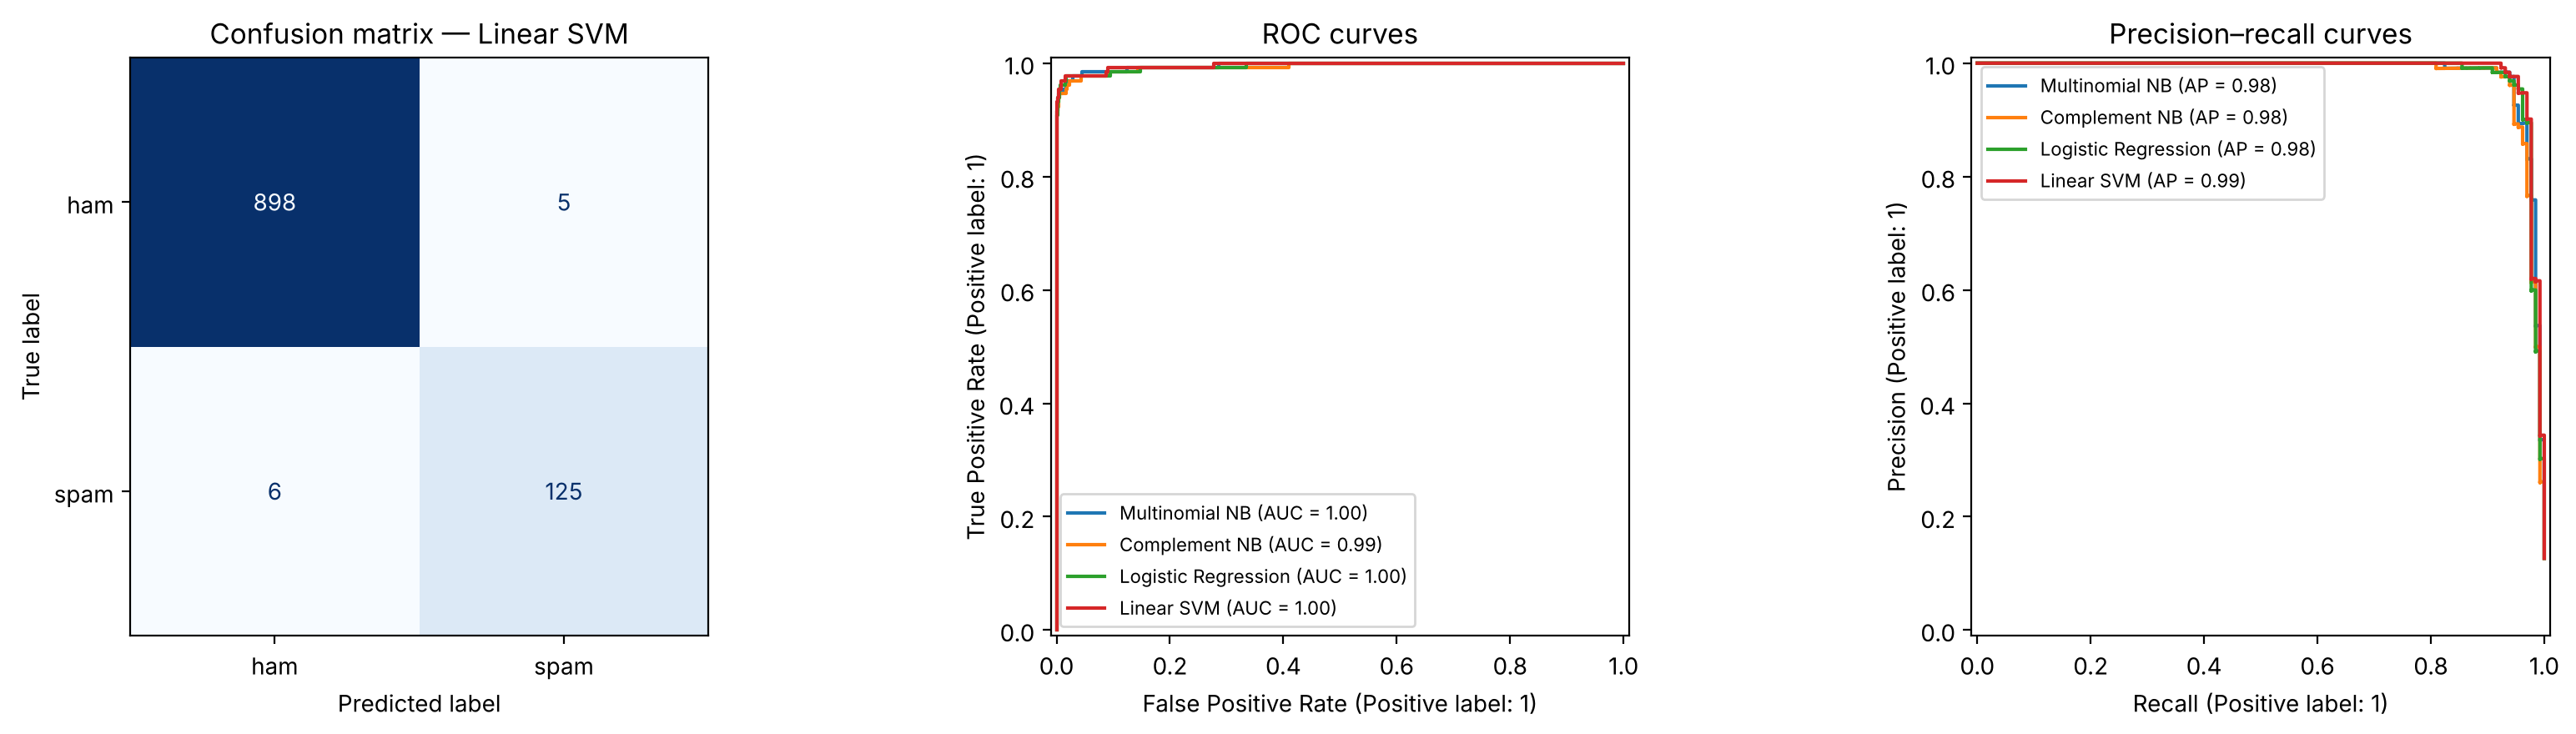

In [8]:
best_name = test_results.index[0]
best = fitted[best_name]
best_pred = best.predict(X_test)
print("Best model:", best_name, "\n")
print(classification_report(y_test, best_pred, target_names=["ham", "spam"], digits=4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["ham", "spam"],
                                        cmap="Blues", colorbar=False, ax=ax[0])
ax[0].set_title(f"Confusion matrix — {best_name}")
for name, m in fitted.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax[1])
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax[2])
ax[1].set_title("ROC curves"); ax[2].set_title("Precision–recall curves")
ax[1].legend(fontsize=8); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Error analysis

In [9]:
errors = pd.DataFrame({"text": df.loc[X_test.index, "text"], "true": y_test, "pred": best_pred})
fp = errors[(errors.true == 0) & (errors.pred == 1)]
fn = errors[(errors.true == 1) & (errors.pred == 0)]
print(f"False positives (ham flagged as spam): {len(fp)}")
display(fp[["text"]])
print(f"\nFalse negatives (spam that got through): {len(fn)}")
display(fn[["text"]])

False positives (ham flagged as spam): 5


,text
2888,Your bill at 3 is £33.65 so thats not bad!
3586,Yep then is fine 7.30 or 8.30 for ice age.
564,Waiting for your call.
134,I only haf msn. It's yijue@hotmail.com
1252,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May"



False negatives (spam that got through): 6


,text
2302,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...
3888,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da..."
3330,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S..."
5062,"Latest News! Police station toilet stolen, cops have nothing to go on!"
1812,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
2641,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-C...


False positives are the costlier mistake in a real inbox (a legitimate message gets hidden), which is why
precision on the spam class matters as much as recall.

## 8. What the model learned

In [10]:
lr = fitted["Logistic Regression"]
names = lr.named_steps["tfidf"].get_feature_names_out()
coefs = lr.named_steps["clf"].coef_[0]
word_mask = np.char.startswith(names.astype(str), "word__")
w_names, w_coefs = names[word_mask], coefs[word_mask]
order = np.argsort(w_coefs)
top = pd.DataFrame({
    "spam indicators": [n.replace("word__", "") for n in w_names[order[-15:][::-1]]],
    "ham indicators":  [n.replace("word__", "") for n in w_names[order[:15]]],
})
top

,spam indicators,ham indicators
0,phonetoken,my
1,moneytoken,at
2,urltoken,me
3,text,lt
4,for,gt
5,reply,lt gt
6,your,ok
7,to,got
8,free,lor
9,to phonetoken,that


## 9. Final model: calibrated probabilities and saving

In [11]:
# Wrap the best model so it outputs a spam probability, then refit on all data before saving
final_model = Pipeline([("tfidf", features()),
                        ("clf", CalibratedClassifierCV(LinearSVC(C=1, class_weight="balanced"), cv=5))])
final_model.fit(X_train, y_train)
proba = final_model.predict_proba(X_test)[:, 1]
print("Calibrated SVM test F1 :", round(f1_score(y_test, proba >= 0.5), 4))
print("Calibrated SVM ROC-AUC :", round(roc_auc_score(y_test, proba), 4))

final_model.fit(df["clean"], df["y"])
joblib.dump(final_model, "spam_model.joblib")
print("Saved -> spam_model.joblib")

Calibrated SVM test F1 : 0.9579
Calibrated SVM ROC-AUC : 0.9967


Saved -> spam_model.joblib


## 10. Try it

In [12]:
def predict_message(text: str, model=final_model, threshold: float = 0.5):
    p = model.predict_proba([normalise(text)])[0, 1]
    return ("SPAM" if p >= threshold else "HAM"), round(float(p), 3)

examples = [
    "WINNER!! You have been selected to receive a £900 prize reward! Call 09061701461 to claim now.",
    "URGENT! Your mobile number has won a free iPhone. Text CLAIM to 87121 before midnight",
    "Hey, are we still meeting for lunch at 1? I'll be at the canteen",
    "Can you send me the notes from today's lecture when you get a chance?",
    "Congratulations ur awarded 500 of CD vouchers or 125gift guaranteed & Free entry 2 100 wkly draw txt MUSIC to 87066",
]
for e in examples:
    label, p = predict_message(e)
    print(f"{label:4}  p(spam)={p:<5}  {e[:80]}")

SPAM  p(spam)=1.0    WINNER!! You have been selected to receive a £900 prize reward! Call 09061701461
SPAM  p(spam)=1.0    URGENT! Your mobile number has won a free iPhone. Text CLAIM to 87121 before mid
HAM   p(spam)=0.002  Hey, are we still meeting for lunch at 1? I'll be at the canteen
HAM   p(spam)=0.011  Can you send me the notes from today's lecture when you get a chance?
SPAM  p(spam)=0.993  Congratulations ur awarded 500 of CD vouchers or 125gift guaranteed & Free entry


In [13]:
# Interactive check (uncomment in Colab / Jupyter)
# msg = input("Enter a message: ")
# print(predict_message(msg))

## Conclusions

- After removing duplicates and splitting with stratification, the linear models with combined word + character
  TF-IDF features reach a spam **F1 ≈ 0.96, ROC-AUC ≈ 0.996** on the held-out set; Linear SVM is the best model, with only ~11 mistakes out of 1,034 test messages.
- The majority-class baseline gets ~87% accuracy with zero recall on spam, which shows why F1 / PR-AUC are the metrics to report.
- Character n-grams and the placeholder tokens (phone numbers, money, URLs) carry much of the signal; the top
  spam features are words like *call, free, txt, claim, prize* plus the number/money tokens.
- **Limitations:** this is the 2012 UK SMS corpus, so slang and scam formats differ from modern messages or tweets.
  A model meant for Twitter would need tweet data and features such as account metadata.
- **Next steps:** fine-tune a small transformer (e.g. DistilBERT) and compare against the linear baseline; tune the
  decision threshold for a target false-positive rate.